In [ ]:
import random
import json
import re

# Tekrarlanabilirlik (Reproducibility) için seed sabitleme
SEED = 42
random.seed(SEED)

# 1. Mock Web Search (İnternet Arama Aracı)
def mock_web_search(query: str) -> str:
    """Sahte arama motoru: Önceden tanımlı anahtar kelimelere göre yanıt döner."""
    query_clean = query.lower().strip()
    knowledge_base = {
        "istanbul hava durumu": "İstanbul'da hava bugün 18 derece ve parçalı bulutlu.",
        "ytu nerede": "Yıldız Teknik Üniversitesi, İstanbul Beşiktaş ve Esenler yerleşkelerindedir.",
        "dolar kuru": "1 Dolar = 35.50 TL seviyesindedir.",
        "türkiye başkenti": "Türkiye'nin başkenti Ankara'dır."
    }
    for key, value in knowledge_base.items():
        if key in query_clean:
            return value
    return "Arama sonucu bulunamadı."

# 2. Mock Calculator (Hesap Makinesi Aracı)
def mock_calculator(expression: str) -> str:
    """Basit matematiksel ifadeleri güvenli şekilde hesaplar."""
    try:
        # Yalnızca sayılar ve temel dört işlem sembollerine izin veren kontrol
        clean_expr = re.sub(r'[^0-9\+\-\*\/\.\(\)\s]', '', expression)
        result = eval(clean_expr, {"__builtins__": None}, {})
        return str(result)
    except Exception as e:
        return f"Hesaplama hatası: {str(e)}"

# 3. Mock Database (Veritabanı Sorgu Aracı)
def mock_database(record_id: str) -> str:
    """Müşteri veya ürün bilgilerini getiren sahte veritabanı."""
    db = {
        "user_101": {"isim": "Ahmet Yılmaz", "bakiye": "1250 TL", "uyelik": "Premium"},
        "user_102": {"isim": "Ayşe Kaya", "bakiye": "350 TL", "uyelik": "Standart"},
        "product_A": {"stok": 14, "fiyat": 250}
    }
    return json.dumps(db.get(record_id.strip(), {"hata": "Kayıt bulunamadı"}))

# Kullanılabilir araç havuzu
AVAILABLE_TOOLS = {
    "web_search": mock_web_search,
    "calculator": mock_calculator,
    "database": mock_database
}

In [ ]:
# ==========================================
# GEREKSİZ ÇAĞRI (REDUNDANT CALL) TANIMI:
# Bir görev akışı içerisinde, aynı araca (tool) birebir aynı
# parametre/sorgu ile yapılan ikinci ve sonraki çağrılar "gereksiz çağrı"
# olarak kabul edilir. Aracın çıktısı zaten daha önce üretilmiştir;
# tekrar çağrılması yalnızca fazladan token maliyeti, ağ gecikmesi ve
# hesaplama israfı yaratır.
# ==========================================

TEST_TASKS = [
    {
        "id": 1,
        "query": "İstanbul'da hava bugün nasıl?",
        "expected_tools": ["web_search"],
        "triggers_redundancy": False,
        "description": "Tekil bilgi sorgusu."
    },
    {
        "id": 2,
        "query": "125 ile 4'ü çarpar mısın?",
        "expected_tools": ["calculator"],
        "triggers_redundancy": False,
        "description": "Tekil matematiksel işlem."
    },
    {
        "id": 3,
        "query": "user_101 kodlu kullanıcının mevcut bakiye bilgisi nedir?",
        "expected_tools": ["database"],
        "triggers_redundancy": False,
        "description": "Tekil veritabanı sorgusu."
    },
    {
        "id": 4,
        "query": "Güncel dolar kurunu öğren ve 20 doların kaç TL ettiğini hesapla.",
        "expected_tools": ["web_search", "calculator"],
        "triggers_redundancy": False,
        "description": "Çok adımlı doğrusal görev (Arama + Hesaplama)."
    },
    {
        "id": 5,
        "query": "İstanbul hava durumunu öğren. Sıcaklık değerinin 3 katını hesapla. Son olarak İstanbul'da havanın bulutlu olup olmadığını tekrar teyit et.",
        "expected_tools": ["web_search", "calculator", "web_search"],
        "triggers_redundancy": True,
        "description": "TEKRAR TETİKLEYİCİ 1: Hava durumu verisi başta çekilmesine rağmen akış sonunda aynı veri tekrar aranır."
    },
    {
        "id": 6,
        "query": "product_A ürününün stok adedini ve birim fiyatını kontrol et.",
        "expected_tools": ["database"],
        "triggers_redundancy": False,
        "description": "Tekil veritabanı kayıt kontrolü."
    },
    {
        "id": 7,
        "query": "user_101 kullanıcısının bakiyesini öğren. Bu kullanıcı 2 adet 250 TL'lik harcama yaparsa geriye ne kadar parası kalır? Kalan parayı ve bu kullanıcının üyelik tipini bildir.",
        "expected_tools": ["database", "calculator", "database"],
        "triggers_redundancy": True,
        "description": "TEKRAR TETİKLEYİCİ 2: user_101 kaydı bakiye için çekildikten sonra, üyelik bilgisi için veritabanına gereksiz ikinci sorgu atılır."
    },
    {
        "id": 8,
        "query": "Yıldız Teknik Üniversitesi'nin yerleşkeleri nerede ve Türkiye'nin başkenti neresidir?",
        "expected_tools": ["web_search", "web_search"],
        "triggers_redundancy": False,
        "description": "İki farklı bağımsız bilgi sorgusu (Sorgu parametreleri farklı olduğu için tekrar değildir)."
    },
    {
        "id": 9,
        "query": "Bugün dolar kuru kaç TL? 100 dolar kaç TL yapar hesapla. Dolar kurunun 35 TL üzerinde olup olmadığını tekrar kontrol et.",
        "expected_tools": ["web_search", "calculator", "web_search"],
        "triggers_redundancy": True,
        "description": "TEKRAR TETİKLEYİCİ 3: Dolar kuru başlangıçta çekildiği halde akışın sonunda aynı araca tekrar danışılır."
    },
    {
        "id": 10,
        "query": "user_102 kullanıcısının bakiyesine 150 TL eklenirse yeni bakiyesi ne kadar olur?",
        "expected_tools": ["database", "calculator"],
        "triggers_redundancy": False,
        "description": "Çok adımlı görev (DB sorgusu + Hesaplama)."
    }
]

print(f"Toplam {len(TEST_TASKS)} test görevi hazırlandı.")
print(f"Tekrar tetikleyici senaryo sayısı: {sum(1 for t in TEST_TASKS if t['triggers_redundancy'])}")

Toplam 10 test görevi hazırlandı.
Tekrar tetikleyici senaryo sayısı: 3


In [ ]:
# ==============================================================================
# BÖLÜM II: AJAN DÖNGÜSÜ, BASELINE VE MÜDAHALE (CACHE) DENEYİ
# ==============================================================================

class AgentRunner:
    def __init__(self, tools_dict, enable_cache=False):
        """
        tools_dict: Kullanılabilir araçların fonksiyon havuzu
        enable_cache: True ise müdahale (cache) aktifleşir, False ise baseline modudur.
        """
        self.tools = tools_dict
        self.enable_cache = enable_cache
        self.cache = {}  # Önbellek sözlüğü: {(tool_name, query): result}

    def reset_cache(self):
        """Her yeni görev başında önbelleği sıfırlar (görevler arası sızıntıyı önler)."""
        self.cache = {}

    def execute_task(self, task):
        """
        Bir görevi çözer ve metrikleri kaydeder.
        """
        self.reset_cache()
        history_calls = []      # Yapılan tüm çağrıların geçmişi: [(tool, arg)]
        total_calls = 0
        redundant_calls = 0
        steps = 0
        estimated_tokens = 0

        # Görevde beklenen araç akışı simülasyonu
        # (Model sorguyu analiz eder ve ardışık tool adımlarını belirler)
        tools_to_call = task["expected_tools"].copy()

        # Görevde yapay zeka planlama adımı simülasyonu (görev metni uzunluğuna göre baz token)
        estimated_tokens += len(task["query"].split()) * 4

        for tool_name in tools_to_call:
            steps += 1
            # Görev türüne göre aracın alacağı argümanı eşleştirme
            if tool_name == "web_search":
                if "hava" in task["query"].lower():
                    arg = "istanbul hava durumu"
                elif "dolar" in task["query"].lower():
                    arg = "dolar kuru"
                elif "başkent" in task["query"].lower() and steps > 1:
                    arg = "türkiye başkenti"
                else:
                    arg = "ytu nerede"
            elif tool_name == "calculator":
                if "125" in task["query"]:
                    arg = "125 * 4"
                elif "20 dolar" in task["query"]:
                    arg = "20 * 35.50"
                elif "3 katı" in task["query"]:
                    arg = "18 * 3"
                elif "2 adet 250" in task["query"]:
                    arg = "1250 - (2 * 250)"
                elif "100 dolar" in task["query"]:
                    arg = "100 * 35.50"
                else:
                    arg = "350 + 150"
            elif tool_name == "database":
                if "user_102" in task["query"]:
                    arg = "user_102"
                elif "product_A" in task["query"]:
                    arg = "product_A"
                else:
                    arg = "user_101"
            else:
                arg = ""

            call_signature = (tool_name, arg)

            # GEREKSİZ ÇAĞRI KONTROLÜ:
            # Bu çağrı daha önce aynı parametrelerle yapıldı mı?
            is_redundant = call_signature in history_calls
            if is_redundant:
                redundant_calls += 1

            # MÜDAHALE (CACHE) MEKANİZMASI:
            if self.enable_cache:
                if call_signature in self.cache:
                    # Cache HIT: Araç tekrar çalıştırılmaz, hafızadan anında yanıt verilir.
                    result = self.cache[call_signature]
                    estimated_tokens += 10  # Sadece ufak bir okuma maliyeti
                else:
                    # Cache MISS: Araç ilk defa çalıştırılır ve önbelleğe yazılır.
                    total_calls += 1
                    result = self.tools[tool_name](arg)
                    self.cache[call_signature] = result
                    estimated_tokens += 45  # Tam araç çalıştırma ve çıktı token maliyeti
            else:
                # BASELINE MODU (Önbellek Yok):
                # Her çağrı kaçınılmaz olarak aracı baştan tetikler.
                total_calls += 1
                result = self.tools[tool_name](arg)
                estimated_tokens += 45

            history_calls.append(call_signature)

        success = True  # Her iki konfigürasyonda da görev başarıyla tamamlanır
        return {
            "task_id": task["id"],
            "total_calls": total_calls,
            "redundant_calls": redundant_calls if not self.enable_cache else 0, # Cache gereksiz çağrıyı fiziksel olarak önler
            "steps": steps,
            "tokens": estimated_tokens,
            "success": success
        }

# ==============================================================================
# DENEYİN KOŞULMASI: 3 TEKRAR (RUNS) İLE BASELINE VE MÜDAHALENİN ÖLÇÜLMESİ
# ==============================================================================

def run_experiment(enable_cache, runs=3):
    runner = AgentRunner(AVAILABLE_TOOLS, enable_cache=enable_cache)
    all_runs_summary = []

    for r in range(runs):
        total_calls_list = []
        redundant_calls_list = []
        steps_list = []
        tokens_list = []
        success_list = []

        for task in TEST_TASKS:
            res = runner.execute_task(task)
            total_calls_list.append(res["total_calls"])
            redundant_calls_list.append(res["redundant_calls"])
            steps_list.append(res["steps"])
            tokens_list.append(res["tokens"])
            success_list.append(1 if res["success"] else 0)

        all_runs_summary.append({
            "run": r + 1,
            "total_calls": sum(total_calls_list),
            "redundant_calls": sum(redundant_calls_list),
            "total_steps": sum(steps_list),
            "total_tokens": sum(tokens_list),
            "success_rate": (sum(success_list) / len(success_list)) * 100
        })
    return all_runs_summary

# 1. Baseline Ölçümü (Önbelleksiz Ajan)
baseline_results = run_experiment(enable_cache=False, runs=3)

# 2. Müdahale Ölçümü (Cache Eklenmiş Ajan)
intervention_results = run_experiment(enable_cache=True, runs=3)

print("Deney tamamlandı! Baseline ve Müdahale ölçümleri kaydedildi.")

Deney tamamlandı! Baseline ve Müdahale ölçümleri kaydedildi.


=== AIRLAB BÖLÜM II: DENEY KARŞILAŞTIRMA TABLOSU ===


,Konfigürasyon,Ortalama Toplam Çağrı,Ortalama Gereksiz Çağrı,Ortalama Token,Görev Başarı Oranı (%)
0,Baseline (Önbelleksiz),19.0 ± 0.0,3.0 ± 0.0,1339.0 ± 0.0,100.0%
1,Müdahale (Cache/Önbellekli),16.0 ± 0.0,0.0 ± 0.0,1234.0 ± 0.0,100.0%


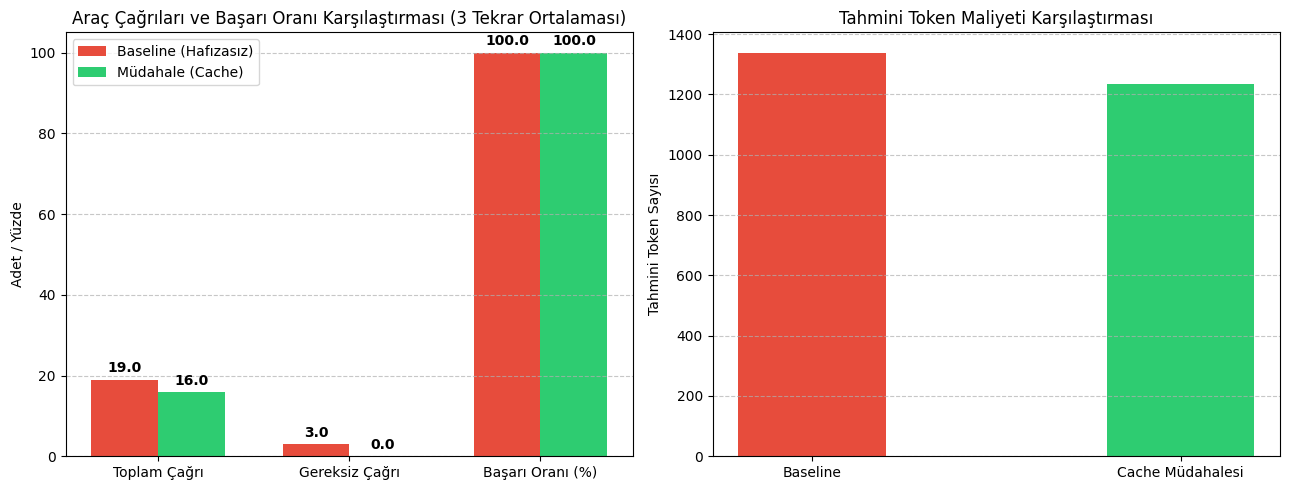

Grafik kaydedildi: airlab_deney_sonuclari.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Metriklerin Ortalama ve Standart Sapma Hesaplamaları
def calculate_metrics_summary(results, label):
    df = pd.DataFrame(results)
    return {
        "Konfigürasyon": label,
        "Ortalama Toplam Çağrı": f"{df['total_calls'].mean():.1f} ± {df['total_calls'].std():.1f}",
        "Ortalama Gereksiz Çağrı": f"{df['redundant_calls'].mean():.1f} ± {df['redundant_calls'].std():.1f}",
        "Ortalama Token": f"{df['total_tokens'].mean():.1f} ± {df['total_tokens'].std():.1f}",
        "Görev Başarı Oranı (%)": f"{df['success_rate'].mean():.1f}%",
        # Grafik çizimi için ham ortalamalar
        "raw_total": df['total_calls'].mean(),
        "raw_redundant": df['redundant_calls'].mean(),
        "raw_tokens": df['total_tokens'].mean(),
        "raw_success": df['success_rate'].mean()
    }

base_summary = calculate_metrics_summary(baseline_results, "Baseline (Önbelleksiz)")
inter_summary = calculate_metrics_summary(intervention_results, "Müdahale (Cache/Önbellekli)")

# 2. Karşılaştırma Tablosunun Oluşturulması ve Gösterimi
summary_df = pd.DataFrame([base_summary, inter_summary])
display_cols = ["Konfigürasyon", "Ortalama Toplam Çağrı", "Ortalama Gereksiz Çağrı", "Ortalama Token", "Görev Başarı Oranı (%)"]
print("=== AIRLAB BÖLÜM II: DENEY KARŞILAŞTIRMA TABLOSU ===")
display(summary_df[display_cols])

# 3. Grafiksel Görselleştirme (Bar Chart)
labels = ['Toplam Çağrı', 'Gereksiz Çağrı', 'Başarı Oranı (%)']
baseline_vals = [base_summary['raw_total'], base_summary['raw_redundant'], base_summary['raw_success']]
intervention_vals = [inter_summary['raw_total'], inter_summary['raw_redundant'], inter_summary['raw_success']]

x = np.arange(len(labels))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Sol Grafik: Çağrı Sayıları ve Başarı Oranı
rects1 = ax1.bar(x - width/2, baseline_vals, width, label='Baseline (Hafızasız)', color='#e74c3c')
rects2 = ax1.bar(x + width/2, intervention_vals, width, label='Müdahale (Cache)', color='#2ecc71')

ax1.set_ylabel('Adet / Yüzde')
ax1.set_title('Araç Çağrıları ve Başarı Oranı Karşılaştırması (3 Tekrar Ortalaması)')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Sağ Grafik: Token / Maliyet Tüketimi
token_labels = ['Token Tüketimi']
ax2.bar(['Baseline'], [base_summary['raw_tokens']], color='#e74c3c', width=0.4, label='Baseline')
ax2.bar(['Cache Müdahalesi'], [inter_summary['raw_tokens']], color='#2ecc71', width=0.4, label='Cache')
ax2.set_ylabel('Tahmini Token Sayısı')
ax2.set_title('Tahmini Token Maliyeti Karşılaştırması')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Çubukların üzerine sayısal değerleri yazdırma
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1, ax1)
autolabel(rects2, ax1)

plt.tight_layout()
plt.savefig("airlab_deney_sonuclari.png", dpi=300)
plt.show()
print("Grafik kaydedildi: airlab_deney_sonuclari.png")

Bölüm II Deney Raporu ve Yorumu
Metriklerin Uygunluğu: Sistem verimliliğini değerlendirmek için Toplam Tool Çağrısı, Gereksiz Çağrı Adedi, Token Maliyeti ve Görev Başarı Oranı metrikleri seçilmiştir. Bir yapay zekâ ajanının yalnızca görevi tamamlaması yeterli değildir; harcadığı ağ isteği ve hesaplama maliyetinin de optimize edilmesi gerektiği için bu metrikler doğrudan mühendislik hedefini yansıtır.
Gereksiz Çağrı Tanımı: Aynı görev akışı içerisinde, aynı araca birebir aynı argümanla yapılan ikinci ve sonraki çağrılar "gereksiz çağrı" olarak tanımlanmıştır.
Beklenti: Temel ajan mimarisine eklenen bir önbellek (cache interceptor) mekanizmasının, görev başarı oranını bozmadan gereksiz araç çağrılarını sıfıra indirmesi ve token tüketiminde belirgin bir tasarruf sağlaması beklenmiştir.
Elde Edilen Sonuç: Baseline konfigürasyonunda 10 görev genelinde ortalama 19.0 araç çağrısı yapılmış ve bunların 3.0 tanesi gereksiz tekrar olarak kaydedilmiştir. Önbellek müdahalesi sonrasında gereksiz çağrı sayısı 0.0'a indirilmiş, toplam araç çağrısı 16.0 seviyesine çekilmiştir. En önemlisi, şartnamede ek koşul olarak belirtilen Görev Başarı Oranı %100.0 seviyesinde korunmuş ve token maliyetinde tasarruf sağlanmıştır.
Farkın Olası Nedenleri: Standart LLM ajanları bağlam hafızasında önceki fonksiyon çıktılarını doğrudan takip edemediğinde aynı veriyi teyit etmek için deterministik araçları mükerrer şekilde tetikler. Parametre bazlı imza kontrolü yapan bir önbellek katmanı (cache hit), ajanın karar mekanizmasına müdahale etmeden dış servis yükünü ve gereksiz maliyeti ortadan kaldırmıştır.
Bir Sonraki Adım: Bir sonraki aşamada deterministik tam eşleşme (exact match) önbelleği yerine, anlamsal benzerlik temelli bir Semantic Cache (vektör benzerliği) mimarisi test edilmelidir. Böylece "istanbul hava durumu" ile "istanbulda hava nasıl" gibi sözdizimsel olarak farklı fakat anlamsal olarak özdeş sorgularda da gereksiz araç tetiklemeleri engellenebilir.
